# 03 — Eksp. 2: Variasi Kandidat Top-k & Trade-off Akurasi vs Latency (RQ3)

- **Model:** tiga checkpoint seed Eksp. 1 per arsitektur, **tanpa training ulang**.
- **Parameter:** k ∈ {20, 50, 100} saat inferensi.
- **Efektivitas:** rata-rata 3 seed; **latency & memori:** run seed 42 (diukur di notebook 02 pada L4).
- **Baseline:** k = 20 dan BM25 saja.

**Cara kerja:** karena cross-encoder bersifat *pointwise*, skor sebuah passage tidak bergantung pada kandidat lain. Me-rerank top-k sama dengan mengambil skor tersimpan untuk kandidat BM25 peringkat 1..k lalu mengurutkannya. Kandidat peringkat k+1..100 ditempelkan di bawahnya dengan urutan BM25 asli (agar MAP@100/Recall@100 tetap sebanding). nDCG@10 dan MRR@10 hanya dipengaruhi top-k yang di-rerank.

> Notebook ini tidak memerlukan GPU.

## 1. Setup

In [1]:
!pip -q install pytrec-eval-terrier

In [2]:
# Mount Google Drive: semua data, skor, dan hasil disimpan di sini agar aman
# bila sesi Colab terputus.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

BASE_DIR    = '/content/drive/MyDrive/MIRACL_Reranking'   # ubah bila perlu
DATA_DIR    = f'{BASE_DIR}/data'      # topics, qrels, BM25 run, passages, training pairs
SCORES_DIR  = f'{BASE_DIR}/scores'    # skor cross-encoder per run (Dev top-100)
RESULTS_DIR = f'{BASE_DIR}/results'   # metrik (JSON), tabel (CSV), log
FIG_DIR     = f'{BASE_DIR}/figures'   # grafik (PNG)
for d in [DATA_DIR, SCORES_DIR, RESULTS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
print('BASE_DIR =', BASE_DIR)

BASE_DIR = /content/drive/MyDrive/MIRACL_Reranking


In [4]:
import json
import pandas as pd

def read_qrels(path):
    """Baca qrels format TREC (qid Q0 docid rel) -> {qid: {docid: rel}}."""
    qrels = {}
    with open(path) as f:
        for line in f:
            p = line.split()
            if len(p) < 4:
                continue
            qrels.setdefault(str(p[0]), {})[p[2]] = int(p[3])
    return qrels

def read_run(path):
    """Baca run format TREC -> {qid: [(docid, score), ...]} terurut berdasarkan rank."""
    tmp = {}
    with open(path) as f:
        for line in f:
            qid, _, docid, rank, score, _tag = line.split()
            tmp.setdefault(qid, []).append((int(rank), docid, float(score)))
    return {q: [(d, s) for _, d, s in sorted(v)] for q, v in tmp.items()}

topics = pd.read_parquet(f'{DATA_DIR}/topics.parquet')            # qid, split, query
QUERY  = dict(zip(topics.qid, topics['query']))
with open(f'{DATA_DIR}/splits.json') as f:
    SPLITS = json.load(f)
qrels_train = read_qrels(f'{DATA_DIR}/qrels.train.tsv')
qrels_dev   = read_qrels(f'{DATA_DIR}/qrels.dev.tsv')
bm25_train  = read_run(f'{DATA_DIR}/run.bm25.train.top100.txt')
bm25_dev    = read_run(f'{DATA_DIR}/run.bm25.dev.top100.txt')
print({k: len(v) for k, v in SPLITS.items()})
print('Dev queries di run BM25:', len(bm25_dev))

{'train': 3664, 'val': 407, 'dev': 960, 'train_25': 916, 'train_50': 1832}
Dev queries di run BM25: 960


In [5]:
import numpy as np
import pandas as pd
import pytrec_eval

def ranking_to_run(ranking):
    """{qid: [docid urut]} -> {qid: {docid: skor}} dengan skor menurun sesuai rank,
    sehingga pytrec_eval memakai urutan persis seperti daftar (tanpa efek tie)."""
    return {q: {d: float(len(docs) - i) for i, d in enumerate(docs)}
            for q, docs in ranking.items()}

def evaluate(ranking, qrels, recall_ks=(20, 50, 100)):
    """Hitung nDCG@10, MRR@10, MAP@100, Recall@k.

    ranking : {qid: [docid, ...]} terurut (maks. 100 dokumen)
    qrels   : {qid: {docid: rel}}
    Hanya kueri yang punya >=1 dokumen relevan yang dievaluasi; kueri yang
    tidak ada di ranking diberi skor 0 (bukan dibuang).
    Return: (rata-rata dict, DataFrame per kueri)
    """
    qids = sorted(q for q, rels in qrels.items() if any(r > 0 for r in rels.values()))
    q_sub = {q: qrels[q] for q in qids}
    full = ranking_to_run({q: ranking.get(q, []) for q in qids})
    top10 = ranking_to_run({q: ranking.get(q, [])[:10] for q in qids})
    # pytrec_eval melewati kueri dengan run kosong -> isi dummy agar tetap terhitung 0
    for run in (full, top10):
        for q in qids:
            if not run[q]:
                run[q] = {'__none__': 0.0}

    rec_spec = 'recall.' + ','.join(str(k) for k in recall_ks)
    ev_full = pytrec_eval.RelevanceEvaluator(q_sub, {'ndcg_cut.10', 'map_cut.100', rec_spec})
    ev_top10 = pytrec_eval.RelevanceEvaluator(q_sub, {'recip_rank'})
    r_full, r_top10 = ev_full.evaluate(full), ev_top10.evaluate(top10)

    rows = []
    for q in qids:
        row = {'qid': q,
               'ndcg@10': r_full[q]['ndcg_cut_10'],
               'mrr@10': r_top10[q]['recip_rank'],
               'map@100': r_full[q]['map_cut_100']}
        for k in recall_ks:
            row[f'recall@{k}'] = r_full[q][f'recall_{k}']
        rows.append(row)
    per_q = pd.DataFrame(rows).set_index('qid')
    return per_q.mean().to_dict(), per_q

In [6]:
import matplotlib.pyplot as plt

# Warna tetap per entitas (tidak berubah antar grafik)
COLORS = {'BM25': '#7a7974', 'mBERT': '#2a78d6', 'mDeBERTa': '#eb6834'}
MARKERS = {'BM25': 's', 'mBERT': 'o', 'mDeBERTa': '^'}
plt.rcParams.update({
    'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'lines.linewidth': 2, 'lines.markersize': 8, 'font.size': 10,
})
MODEL_LABEL = {'mbert': 'mBERT', 'mdeberta': 'mDeBERTa'}

In [7]:
K_LIST = [20, 50, 100]
SEEDS = [42, 100, 2026]
MODEL_KEYS = ['mbert', 'mdeberta']

def load_scores(model_key, seed):
    path = f'{SCORES_DIR}/{model_key}_frac100_seed{seed}.dev_top100.parquet'
    return pd.read_parquet(path) if os.path.exists(path) else None

def topk_ranking(scores, k):
    """Rerank kandidat BM25 peringkat 1..k memakai skor cross-encoder,
    lalu tempelkan peringkat k+1..100 dalam urutan BM25."""
    ranking = {}
    for q, g in scores.groupby('qid', sort=False):
        g = g.sort_values('bm25_rank')
        head = g[g.bm25_rank <= k].sort_values(['ce_score', 'bm25_rank'], ascending=[False, True])
        tail = g[g.bm25_rank > k]
        ranking[q] = head.docid.tolist() + tail.docid.tolist()
    return ranking

available = {(m, s): load_scores(m, s) for m in MODEL_KEYS for s in SEEDS}
print('Run tersedia:', [f'{m}-{s}' for (m, s), v in available.items() if v is not None])

Run tersedia: ['mbert-42', 'mbert-100', 'mbert-2026', 'mdeberta-42', 'mdeberta-100', 'mdeberta-2026']


## 2. Batas atas: Recall@k BM25 & nDCG@10 oracle

In [8]:
bm25_rank = {q: [d for d, _ in v] for q, v in bm25_dev.items()}
bm25_mean, bm25_perq = evaluate(bm25_rank, qrels_dev)

def oracle_ranking(k):
    """Urutan ideal kandidat top-k (semua relevan di atas) = batas atas reranker untuk k tsb."""
    out = {}
    for q, docs in bm25_rank.items():
        head = docs[:k]
        rel = [d for d in head if qrels_dev.get(q, {}).get(d, 0) > 0]
        out[q] = rel + [d for d in head if d not in rel] + docs[k:]
    return out

rows = []
for k in K_LIST:
    o_mean, _ = evaluate(oracle_ranking(k), qrels_dev)
    rows.append({'k': k, 'BM25 Recall@k': bm25_mean[f'recall@{k}'],
                 'Oracle nDCG@10 (batas atas)': o_mean['ndcg@10'],
                 'Kueri tanpa relevan di top-k': int((bm25_perq[f'recall@{k}'] == 0).sum())})
upper = pd.DataFrame(rows).set_index('k')
print(f"BM25 saja: nDCG@10 = {bm25_mean['ndcg@10']:.4f}, MRR@10 = {bm25_mean['mrr@10']:.4f}")
upper.round(4)

BM25 saja: nDCG@10 = 0.4486, MRR@10 = 0.5306


,BM25 Recall@k,Oracle nDCG@10 (batas atas),Kueri tanpa relevan di top-k
k,,,
20,0.6788,0.7272,124
50,0.8295,0.8583,57
100,0.9041,0.9211,31


## 3. Efektivitas per k (rata-rata ± simpangan baku 3 seed)

In [9]:
records = []
for (m, s), sc in available.items():
    if sc is None:
        continue
    for k in K_LIST:
        mean, perq = evaluate(topk_ranking(sc, k), qrels_dev)
        perq.to_csv(f'{RESULTS_DIR}/{m}_frac100_seed{s}.k{k}.per_query.csv')
        records.append({'model': MODEL_LABEL[m], 'seed': s, 'k': k, **mean})
eff_df = pd.DataFrame(records)
eff_df.to_csv(f'{RESULTS_DIR}/exp2_effectiveness_by_seed.csv', index=False)

metrics = ['ndcg@10', 'mrr@10', 'map@100']
exp2 = eff_df.groupby(['model', 'k'])[metrics].agg(['mean', 'std'])
exp2.to_csv(f'{RESULTS_DIR}/exp2_effectiveness.csv')
exp2.round(4)

ndcg@10          mrr@10         map@100        
                mean     std    mean     std    mean     std
model    k                                                  
mBERT    20   0.5587  0.0023  0.6686  0.0029  0.4859  0.0028
         50   0.5948  0.0045  0.6953  0.0041  0.5166  0.0054
         100  0.5947  0.0056  0.6956  0.0058  0.5159  0.0051
mDeBERTa 20   0.5668  0.0053  0.6747  0.0055  0.4956  0.0055
         50   0.6018  0.0057  0.7045  0.0064  0.5270  0.0057
         100  0.6035  0.0060  0.7053  0.0064  0.5301  0.0061

## 4. Efisiensi per k (seed 42, NVIDIA L4)

In [10]:
eff_rows = []
for m in MODEL_KEYS:
    p = f'{RESULTS_DIR}/efficiency_{m}.json'
    if not os.path.exists(p):
        print(f'⚠️  {p} belum ada — jalankan notebook 02 (seed 42, 100%) dengan GPU.'); continue
    e = json.load(open(p))
    for k, v in e['by_k'].items():
        eff_rows.append({'model': MODEL_LABEL[m], 'k': int(k), 'n_params_M': e['n_params'] / 1e6,
                         'gpu': e['gpu'], **v})
lat = pd.DataFrame(eff_rows)
if len(lat):
    base = lat[lat.k == 20].set_index('model')
    lat['latency_x_vs_k20'] = lat.apply(lambda r: r.latency_ms_mean / base.loc[r.model, 'latency_ms_mean'], axis=1)
    lat['k_x_vs_k20'] = lat.k / 20
    lat['bm25_recall@k'] = lat.k.map(lambda k: bm25_mean[f'recall@{k}'])
    lat.to_csv(f'{RESULTS_DIR}/exp2_efficiency.csv', index=False)
    display(lat[['model', 'k', 'latency_ms_mean', 'latency_ms_p95', 'throughput_pairs_per_s',
                 'throughput_queries_per_s', 'peak_gpu_mem_mb', 'k_x_vs_k20', 'latency_x_vs_k20',
                 'bm25_recall@k']].round(3))

,model,k,latency_ms_mean,latency_ms_p95,throughput_pairs_per_s,throughput_queries_per_s,peak_gpu_mem_mb,k_x_vs_k20,latency_x_vs_k20,bm25_recall@k
0,mBERT,20,40.592,44.855,491.216,24.635,998.172,1.0,1.000,0.679
1,mBERT,50,89.715,96.071,554.192,11.146,1062.391,2.5,2.210,0.830
2,mBERT,100,177.195,187.123,560.357,5.643,1062.391,5.0,4.365,0.904
3,mDeBERTa,20,100.403,107.785,198.594,9.960,1686.496,1.0,1.000,0.679
4,mDeBERTa,50,245.521,258.527,202.504,4.073,1933.316,2.5,2.445,0.830
5,mDeBERTa,100,501.061,519.653,198.165,1.996,1933.316,5.0,4.991,0.904


**Interpretasi RQ3:** bandingkan kolom `k_x_vs_k20` (kandidat naik 2,5× dan 5×) dengan `latency_x_vs_k20`. Hipotesis: latency naik hampir linear, sedangkan kenaikan nDCG@10 melandai mengikuti Recall@k BM25.

## 5. Grafik

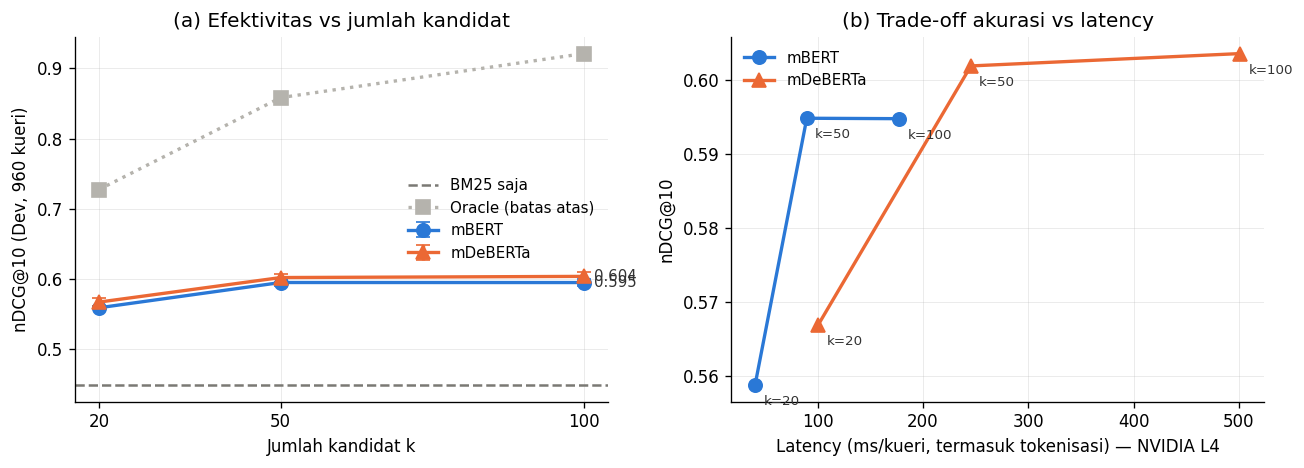

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) nDCG@10 vs k
ax = axes[0]
for m in ['mBERT', 'mDeBERTa']:
    d = exp2.loc[m] if m in exp2.index.get_level_values(0) else None
    if d is None:
        continue
    mu, sd = d[('ndcg@10', 'mean')], d[('ndcg@10', 'std')].fillna(0)
    ax.errorbar(K_LIST, mu.values, yerr=sd.values, color=COLORS[m], marker=MARKERS[m],
                capsize=4, label=m)
    ax.annotate(f'{mu.values[-1]:.3f}', (K_LIST[-1], mu.values[-1]), textcoords='offset points',
                xytext=(6, 0), va='center', fontsize=9, color='#333')
ax.axhline(bm25_mean['ndcg@10'], color=COLORS['BM25'], ls='--', lw=1.5, label='BM25 saja')
ax.plot(K_LIST, upper['Oracle nDCG@10 (batas atas)'].values, color='#b5b3ad', ls=':', marker='s',
        label='Oracle (batas atas)')
ax.set_xticks(K_LIST); ax.set_xlabel('Jumlah kandidat k'); ax.set_ylabel('nDCG@10 (Dev, 960 kueri)')
ax.set_title('(a) Efektivitas vs jumlah kandidat')
ax.legend(frameon=False, fontsize=9)

# (b) trade-off nDCG@10 vs latency
ax = axes[1]
if len(lat):
    for m in ['mBERT', 'mDeBERTa']:
        l = lat[lat.model == m].sort_values('k')
        if not len(l) or m not in exp2.index.get_level_values(0):
            continue
        y = exp2.loc[m][('ndcg@10', 'mean')].reindex(l.k).values
        ax.plot(l.latency_ms_mean, y, color=COLORS[m], marker=MARKERS[m], label=m)
        for x_, y_, k in zip(l.latency_ms_mean, y, l.k):
            ax.annotate(f'k={k}', (x_, y_), textcoords='offset points', xytext=(5, -12), fontsize=8, color='#333')
    ax.set_xlabel('Latency (ms/kueri, termasuk tokenisasi) — NVIDIA L4')
    ax.set_ylabel('nDCG@10')
    ax.set_title('(b) Trade-off akurasi vs latency')
    ax.legend(frameon=False, fontsize=9)
else:
    ax.text(0.5, 0.5, 'Data efisiensi belum tersedia', ha='center', transform=ax.transAxes)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exp2_topk_tradeoff.png', dpi=200, bbox_inches='tight')
plt.show()

In [12]:
# Uji tambahan (deskriptif): apakah kenaikan k signifikan? (per kueri, rata-rata 3 seed, Wilcoxon)
from scipy.stats import wilcoxon
rows = []
for m in MODEL_KEYS:
    per_k = {}
    for k in K_LIST:
        frames = [pd.read_csv(f'{RESULTS_DIR}/{m}_frac100_seed{s}.k{k}.per_query.csv', index_col=0, dtype={'qid': str})['ndcg@10']
                  for s in SEEDS if os.path.exists(f'{RESULTS_DIR}/{m}_frac100_seed{s}.k{k}.per_query.csv')]
        if frames:
            per_k[k] = pd.concat(frames, axis=1).mean(axis=1)
    for a, b in [(20, 50), (50, 100), (20, 100)]:
        if a in per_k and b in per_k:
            diff = per_k[b] - per_k[a]
            p = wilcoxon(per_k[b], per_k[a]).pvalue if (diff != 0).any() else 1.0
            rows.append({'model': MODEL_LABEL[m], 'perbandingan': f'k={b} vs k={a}',
                         'Δ nDCG@10': diff.mean(), 'p (Wilcoxon)': p})
pd.DataFrame(rows).round(4)

,model,perbandingan,Δ nDCG@10,p (Wilcoxon)
0,mBERT,k=50 vs k=20,0.0360,0.0430
1,mBERT,k=100 vs k=50,-0.0001,0.0000
2,mBERT,k=100 vs k=20,0.0360,0.0214
3,mDeBERTa,k=50 vs k=20,0.0350,0.0178
4,mDeBERTa,k=100 vs k=50,0.0017,0.0000
5,mDeBERTa,k=100 vs k=20,0.0367,0.0156
